# Freight Rate Prediction — walkthrough

Predict `posted_rate` for 12,000 loads dated **after every row the model trains on**.

This notebook is a narrative over the tested package in `src/freight_rate/`. It imports
the same code the CLI and the test suite use — it is not a second implementation, so
nothing here can drift from what actually produced the submission.

**Order:** the data → what is wrong with it → how to split it → the model → the result.
Data comes before modelling because on this dataset the data work is worth more than
the algorithm choice.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from freight_rate import load_train, load_validation, load_december_inputs, metrics
from freight_rate.config import RunConfig, PATHS
from freight_rate.pipeline import FreightRatePipeline
from freight_rate.outliers import TargetOutlierDetector
from freight_rate.level import MarketLevelModel
from freight_rate.model import DistanceBaseline, RatePerMileBaseline
from freight_rate.validation import holdout_split, random_kfold_splits
from freight_rate.geo import haversine_miles

TEAL, RUST = "#064A56", "#A6401E"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

train = load_train()
valid = load_validation()
december = load_december_inputs()
print(f"train    {train.shape}   {train.date.min():%Y-%m-%d} .. {train.date.max():%Y-%m-%d}")
print(f"scored   {valid.shape}   {valid.date.min():%Y-%m-%d} .. {valid.date.max():%Y-%m-%d}")
print(f"december {december.shape}")

train    (48000, 14)   2025-01-01 .. 2025-10-31
scored   (12000, 13)   2025-11-01 .. 2025-12-31
december (31, 7)


## 1. The fact that shapes everything

The scored window is strictly *after* the training window. There is no overlap at all.

In [2]:
print("last training date :", train.date.max().date())
print("first scored date  :", valid.date.min().date())
print("overlap            :", train.date.max() >= valid.date.min())
print("scored horizon     :", (valid.date.max() - valid.date.min()).days + 1, "days")

# The scored file also has no target column - that is what we must produce.
print("\ncolumns only in train:", sorted(set(train.columns) - set(valid.columns)))
print("december columns     :", list(december.columns))

last training date : 2025-10-31
first scored date  : 2025-11-01
overlap            : False
scored horizon     : 61 days

columns only in train: ['posted_rate']
december columns     : ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


The December chart rows carry only six inputs — no coordinates, no `market_index`.
**Any feature the model uses has to be reconstructable from those six**, or the chart
cannot be produced. That constraint is enforced by a test.

## 2. What the target looks like

Rate is a power law in distance. This one relationship is most of the signal.

log(rate) = 1.6508 + 0.8711 * log(distance)
R^2 = 0.9359   residual sigma = 0.1689   kurtosis = 51.1


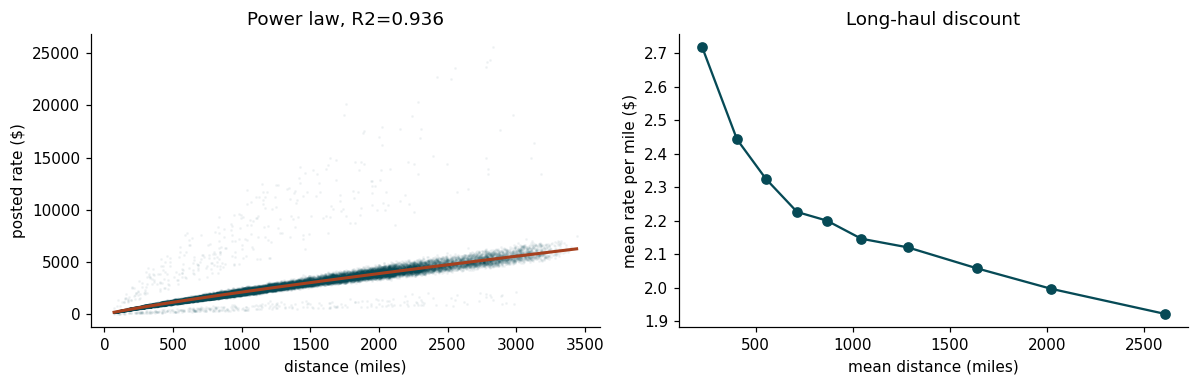

In [3]:
x, y = np.log(train.distance), np.log(train.posted_rate)
slope, intercept = np.polyfit(x, y, 1)
r2 = np.corrcoef(x, y)[0, 1] ** 2
resid = y - (intercept + slope * x)
print(f"log(rate) = {intercept:.4f} + {slope:.4f} * log(distance)")
print(f"R^2 = {r2:.4f}   residual sigma = {resid.std():.4f}   kurtosis = {resid.kurt():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(train.distance, train.posted_rate, s=1, alpha=.04, color=TEAL)
g = np.linspace(train.distance.min(), train.distance.max(), 200)
ax[0].plot(g, np.exp(intercept + slope*np.log(g)), color=RUST, lw=2)
ax[0].set(xlabel="distance (miles)", ylabel="posted rate ($)", title=f"Power law, R2={r2:.3f}")

d = train.assign(rpm=train.posted_rate/train.distance,
                 dec=pd.qcut(train.distance, 10, labels=False)).groupby("dec").agg(
                 dist=("distance","mean"), rpm=("rpm","mean"))
ax[1].plot(d.dist, d.rpm, marker="o", color=TEAL)
ax[1].set(xlabel="mean distance (miles)", ylabel="mean rate per mile ($)", title="Long-haul discount")
plt.tight_layout(); plt.show()

Rate-per-mile **falls** as distance grows, $2.72 at 226 miles down to $1.92 at 2,606.
That is why the model works in log space and why `log(distance)` is subtracted from the
target rather than left for the tree to rediscover.

## 3. Data quality — the big one

A kurtosis of 51 is not a normal residual. Something is wrong with the labels.

In [4]:
dev = (resid - np.median(resid)).abs()
bands = {f"{lo}-{hi}": int(((dev >= lo) & (dev < hi)).sum())
         for lo, hi in [(0.0,0.2),(0.2,0.3),(0.3,0.4),(0.4,0.5),(0.5,0.7),(0.7,3.0)]}
print("|log residual| distribution:")
for k, v in bands.items():
    print(f"  {k:>8} : {v:6,d}  {'#' * min(60, v // 400)}")
print("\n^ note the EMPTY BAND between 0.3 and 0.7.")
print("  Genuine heavy tails do not leave a clean gap. A mixture does.")

|log residual| distribution:
   0.0-0.2 : 47,194  ############################################################
   0.2-0.3 :    129  
   0.3-0.4 :      0  
   0.4-0.5 :      0  
   0.5-0.7 :      1  
   0.7-3.0 :    676  #

^ note the EMPTY BAND between 0.3 and 0.7.
  Genuine heavy tails do not leave a clean gap. A mixture does.


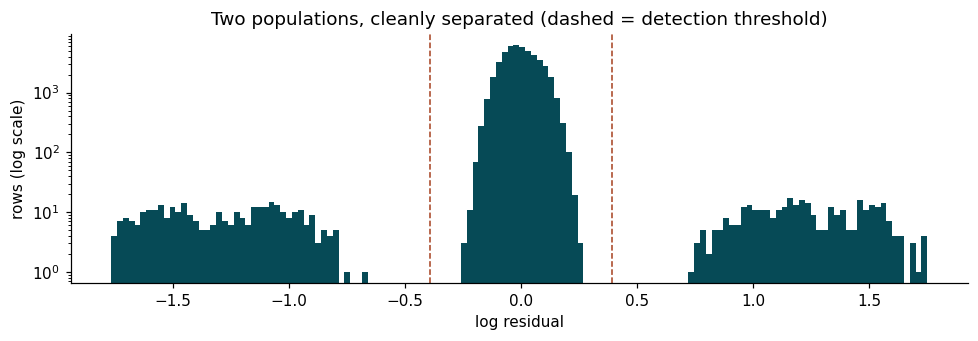

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(resid, bins=140, color=TEAL)
ax.set_yscale("log")
for s in (-1, 1):
    ax.axvline(s * 0.39, color=RUST, ls="--", lw=1)
ax.set(xlabel="log residual", ylabel="rows (log scale)",
       title="Two populations, cleanly separated (dashed = detection threshold)")
plt.tight_layout(); plt.show()

In [6]:
detector = TargetOutlierDetector().fit(train)
print(detector.report_.describe())

flag = detector.flag(train)
print("\nIs it predictable from anything? (if yes, we could model it instead of dropping it)")
for col in ["equipment"]:
    print(f"  by {col}: ", {k: round(v, 4) for k, v in flag.groupby(train[col]).mean().items()})
print("  by month:  ", {k: round(v, 4) for k, v in flag.groupby(train.date.dt.month).mean().items()})
print("\n-> flat everywhere. Nothing predicts it, so it cannot be modelled - only excluded.")

target contamination: 677 / 48,000 rows (1.41%) - 340 inflated, 337 deflated; log-residual sigma 0.1689 -> 0.0738 (threshold 0.391)

Is it predictable from anything? (if yes, we could model it instead of dropping it)
  by equipment:  {'Dry Van': 0.0135, 'Flatbed': 0.0145, 'Reefer': 0.0151}
  by month:   {1: 0.0165, 2: 0.0131, 3: 0.0141, 4: 0.0137, 5: 0.0126, 6: 0.0132, 7: 0.0132, 8: 0.0143, 9: 0.0137, 10: 0.0165}

-> flat everywhere. Nothing predicts it, so it cannot be modelled - only excluded.


**677 rows (1.41%) have a multiplicatively corrupted label** — 340 scaled up 2.2–5.6×,
337 scaled down to 0.17–0.45×. Removing them takes the residual from σ 0.169 / kurtosis 51
to σ 0.074 / kurtosis −0.46, essentially Gaussian.

They are dropped from **training only**, never from scoring. Since nothing predicts which
scored rows are affected, the best prediction for every row is the centre of the *clean*
distribution.

## 4. A feature that looks useful and isn't

In [7]:
print(f"corr(quote_signal, posted_rate) = {np.corrcoef(train.quote_signal, train.posted_rate)[0,1]:+.4f}")
mi = train.dropna(subset=['market_index'])
print(f"corr(market_index, posted_rate) = {np.corrcoef(mi.market_index, mi.posted_rate)[0,1]:+.4f}")

# quote_signal looks plausible because distance carries the estimate, not the signal.
naive = train.quote_signal * train.distance
const = train.quote_signal.mean() * train.distance
mape = lambda p: np.mean(np.abs(p - train.posted_rate) / train.posted_rate) * 100
print(f"\nMAPE using quote_signal * distance : {mape(naive):.2f}%")
print(f"MAPE replacing it with a CONSTANT  : {mape(const):.2f}%")
print("\n-> swapping the feature for a constant costs 0.33pp. It is a decoy; excluded.")

corr(quote_signal, posted_rate) = -0.0399
corr(market_index, posted_rate) = +0.0342

MAPE using quote_signal * distance : 11.37%
MAPE replacing it with a CONSTANT  : 11.70%

-> swapping the feature for a constant costs 0.33pp. It is a decoy; excluded.


## 5. A defect that punishes you for fixing it

111 rows have `distance` more than 1.6× the great-circle figure. That looks like corrupt
mileage. It is not.

In [8]:
gc = pd.Series(
    haversine_miles(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon),
    index=train.index)
ratio = train.distance / gc
bad = train[ratio > 1.6]
print(f"suspicious rows: {len(bad)}")
print(f"their distance runs {bad.distance.min():.0f}-{bad.distance.max():.0f} miles (all SHORT hauls)")
print(f"median circuity overall: {ratio.median():.3f}")

# Compare each suspicious row against the same lane in the clean rows.
good = train[ratio <= 1.6].copy()
good["lane"] = good.pickup + "->" + good.delivery
lane_median = good.groupby("lane").distance.median()
b = bad.assign(lane=bad.pickup + "->" + bad.delivery)
b = b.assign(lane_med=b.lane.map(lane_median)).dropna(subset=["lane_med"])
print(f"\ntheir distance / same-lane median distance: {(b.distance / b.lane_med).median():.3f}")
print("-> only 1.16x the normal distance for that lane. The mileage is FINE.")

# What would "repairing" them cost?
sl, ic = np.polyfit(np.log(good.distance), np.log(good.posted_rate), 1)
err = lambda p: np.mean(np.abs(p - b.posted_rate) / b.posted_rate) * 100
repaired = gc.loc[b.index] * ratio.median()   # what a naive "fix" would substitute
print(f"\nMAPE using the REPORTED distance : {err(np.exp(ic + sl*np.log(b.distance))):.1f}%")
print(f"MAPE after 'repairing' it        : {err(np.exp(ic + sl*np.log(repaired))):.1f}%")
print("\n-> the coordinates are coarse, not the mileage. New Orleans->Shreveport")
print("   great-circles to 7 miles. 'Fixing' distance doubles the error.")

suspicious rows: 111
their distance runs 70-146 miles (all SHORT hauls)
median circuity overall: 1.182

their distance / same-lane median distance: 1.157
-> only 1.16x the normal distance for that lane. The mileage is FINE.

MAPE using the REPORTED distance : 15.4%
MAPE after 'repairing' it        : 31.1%

-> the coordinates are coarse, not the mileage. New Orleans->Shreveport
   great-circles to 7 miles. 'Fixing' distance doubles the error.


## 6. Cold start: cities that only exist in the scored set

In [9]:
seen = set(train.pickup) | set(train.delivery)
unseen = sorted((set(valid.pickup) | set(valid.delivery)) - seen)
touched = valid.pickup.isin(unseen) | valid.delivery.isin(unseen)
print(f"cities only in the scored data ({len(unseen)}): {', '.join(unseen)}")
print(f"scored rows touching one: {touched.sum():,} of {len(valid):,} ({touched.mean():.1%})")
print(f"rows with BOTH ends unseen: {(valid.pickup.isin(unseen) & valid.delivery.isin(unseen)).sum()}")

cities only in the scored data (8): Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego
scored rows touching one: 1,447 of 12,000 (12.1%)
rows with BOTH ends unseen: 0


12% of the loads we must price involve a city with no history. A boosted tree sends an
unknown category down its missing-value branch — and if no training row ever had a missing
city, **that branch was never fitted**. The fix is `city_dropout_rate=0.10`: blank 10% of
training cities so the model learns a real fallback. Worth about $10 MAE on held-out cities (`reports/cold_start.md`).

## 7. The split — the decision that matters most

This is where the usual `train_test_split(X, y, test_size=0.2, random_state=42)` goes wrong.
Let us measure exactly how wrong.

In [10]:
cfg = RunConfig()
contaminated = flag.to_numpy(bool)

def evaluate(split, label):
    tr = train.iloc[split.train_index].reset_index(drop=True)
    ev = train.iloc[split.eval_index].reset_index(drop=True)
    m = contaminated[split.eval_index]
    # The window's own inputs (never its label) are context, as at deployment;
    # without them the pipeline refuses to price a window it has no index for.
    pipe = FreightRatePipeline(cfg).fit(tr, context_frames=(valid, ev.drop(columns=["posted_rate"])))
    pred = pipe.predict(ev)
    res = metrics.compute(ev.posted_rate.to_numpy()[~m], pred[~m])
    print(f"{label:<34} {res.describe()}")
    return res, pipe, ev, pred, m

# (a) the WRONG way - shuffled, ignores time entirely
folds = [evaluate(s, f"RANDOM fold {i+1} (the wrong way)")[0]
         for i, s in enumerate(random_kfold_splits(len(train), n_splits=3, seed=cfg.seed))]
random_mae = float(np.mean([f.mae for f in folds]))
print(f"{'  random 3-fold mean':<34} MAE={random_mae:.2f}")

# (b) the RIGHT way - a date cutoff, 61 days to match the scored window
hold = holdout_split(train.date, cfg.split.holdout_days)
print(f"\n{hold.describe()}")
temporal_res, pipe, ev, pred, mask = evaluate(hold, "TEMPORAL split (honest)")

optimism = (temporal_res.mae - random_mae) / temporal_res.mae
print(f"\n=> random split says ${random_mae:,.2f}; the truth is ${temporal_res.mae:,.2f}.")
print(f"   It understates the error by {optimism:.0%}.")

RANDOM fold 1 (the wrong way)      n=15,776  MAE=31.78  RMSE=46.39  MAPE=1.36%  MedAPE=1.14%  R2=0.9988  bias=-0.67


RANDOM fold 2 (the wrong way)      n=15,778  MAE=31.85  RMSE=46.15  MAPE=1.36%  MedAPE=1.13%  R2=0.9988  bias=+0.57


RANDOM fold 3 (the wrong way)      n=15,769  MAE=31.67  RMSE=45.99  MAPE=1.37%  MedAPE=1.14%  R2=0.9988  bias=+0.23
  random 3-fold mean               MAE=31.76

holdout_61d: train<= 2025-08-31 (38,477 rows) eval 2025-09-01..2025-10-31 (9,523 rows)


TEMPORAL split (honest)            n=9,379  MAE=48.15  RMSE=73.47  MAPE=2.01%  MedAPE=1.62%  R2=0.9971  bias=-36.44

=> random split says $31.76; the truth is $48.15.
   It understates the error by 34%.


**That is the whole lesson.** The random split is not a little optimistic: shuffling lets
October rows train a model that predicts June, and it hides the market drift the model
actually has to extrapolate. The holdout is sized at 61 days because the scored window is
61 days, so the headline number is measured over exactly the horizon it will be judged on.

One more rule, learned the hard way: **the evaluation window must receive its own inputs**
(coordinates and `market_index`, never the label) as context, the way the scored file
carries them for November-December. An earlier version of this validation did not, so the
window's dates were absent from the daily index and every day silently received the global
median. The level was evaluated as a constant it never is at deployment, and the headline
read $38.94 where the deployed configuration measures $48.15 on the same rows. The pipeline
now refuses to price a window it has no index for, and a test pins that.

## 8. What a tree cannot do: extrapolate

Two parts of the target are smooth and keep moving past the training window. A tree is
piecewise-constant, so beyond its last bin it just repeats itself.


level = 0.5854 + 0.000222*t + 0.1440*market_index
  trend only           R2 = 0.2634
  market_index only    R2 = 0.4380
  BOTH                 R2 = 0.7850

trend across the training window: +7.0%


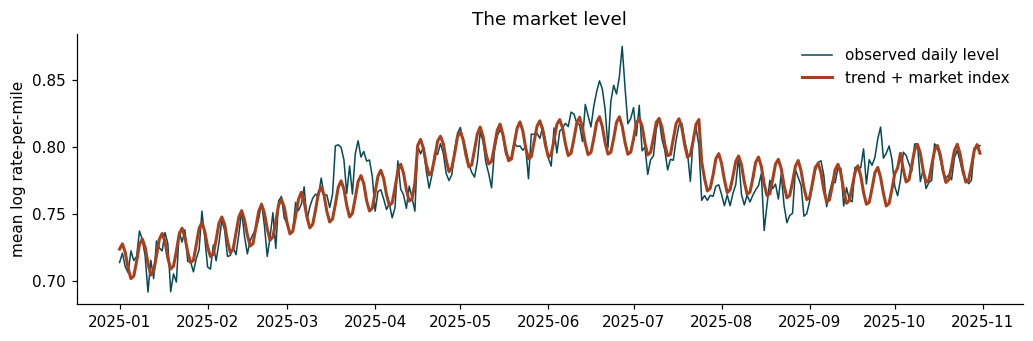

In [11]:
clean = train.loc[~contaminated].copy()
clean["log_rpm"] = np.log(clean.posted_rate) - np.log(clean.distance)
daily = clean.groupby("date").agg(log_rpm=("log_rpm","mean"), mkt=("market_index","mean"))
daily["t"] = (daily.index - daily.index.min()).days

X = np.column_stack([np.ones(len(daily)), daily.t, daily.mkt])
beta, *_ = np.linalg.lstsq(X, daily.log_rpm, rcond=None)
tot = daily.log_rpm.var()
print(f"level = {beta[0]:.4f} + {beta[1]:.6f}*t + {beta[2]:.4f}*market_index")
for name, cols in {"trend only":[0,1], "market_index only":[0,2], "BOTH":[0,1,2]}.items():
    b, *_ = np.linalg.lstsq(X[:,cols], daily.log_rpm, rcond=None)
    print(f"  {name:<20} R2 = {1 - (daily.log_rpm - X[:,cols]@b).var()/tot:.4f}")
print(f"\ntrend across the training window: {100*(np.exp(beta[1]*daily.t.max())-1):+.1f}%")

fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(daily.index, daily.log_rpm, color=TEAL, lw=1, label="observed daily level")
ax.plot(daily.index, X@beta, color=RUST, lw=2, label="trend + market index")
ax.legend(frameon=False); ax.set(ylabel="mean log rate-per-mile", title="The market level")
plt.tight_layout(); plt.show()

Trend alone, index alone and both together fit the daily level to different degrees, and
removing the level entirely costs about $9 of holdout MAE (`reports/model_selection.md`).

The index term is the contested part. Once every evaluation window gets its real index, the
61-day holdout and the rolling folds disagree: trend-only wins the holdout ($40.56 vs $48.15)
and loses the fold mean ($51.19 vs $46.82, with one fold at $80). The index helps where it
swings hard (June-August) and hurts in September-October, where rates held up while the index
fell. The rule applied is that a change is adopted only if it improves the holdout *and* does
not regress the folds, so the level keeps both terms and the disagreement is a stated
limitation (`reports/level_selection.md`).

The level is fitted as an explicit linear model, subtracted from the target, and added back
at prediction time, where it extrapolates by construction.

## 9. The model, against baselines


In [12]:
tr = train.iloc[hold.train_index].reset_index(drop=True)
actual = ev.posted_rate.to_numpy()

rows = {"Gradient boosting (this model)": metrics.compute(actual[~mask], pred[~mask])}
for name, est in [("Log-linear on distance", DistanceBaseline()),
                  ("Median rate-per-mile", RatePerMileBaseline())]:
    est.fit(tr[["distance"]], tr.posted_rate)
    rows[name] = metrics.compute(actual[~mask], est.predict(ev[["distance"]])[~mask])

print(f"{'model':<32}{'MAE':>10}{'RMSE':>10}{'MAPE':>9}{'MedAPE':>9}{'R2':>9}")
for k, v in rows.items():
    print(f"{k:<32}{v.mae:>10.2f}{v.rmse:>10.2f}{v.mape:>8.2f}%{v.median_ape:>8.2f}%{v.r2:>9.4f}")

print(f"\nincluding corrupted labels: {metrics.compute(actual, pred).describe()}")
print("-> mean APE jumps, MEDIAN APE barely moves. That gap IS the contamination.")

model                                  MAE      RMSE     MAPE   MedAPE       R2
Gradient boosting (this model)       48.15     73.47    2.01%    1.62%   0.9971
Log-linear on distance              135.76    183.23    5.87%    5.49%   0.9822
Median rate-per-mile                203.69    295.93    9.27%    7.91%   0.9537

including corrupted labels: n=9,523  MAE=104.08  RMSE=633.30  MAPE=4.51%  MedAPE=1.65%  R2=0.8278  bias=-70.04
-> mean APE jumps, MEDIAN APE barely moves. That gap IS the contamination.


In [13]:
print(pipe.summary.describe())
print("\nerror by equipment:")
print(metrics.stratified(actual[~mask], pred[~mask], ev.equipment[~mask], "equipment")[
      ["n","mae","mape"]].round(3).to_string())

fitted on 37,944 of 38,477 rows [2025-01-01..2025-08-31]
features: 32 (3 categorical: equipment, pickup, delivery)
smearing factor: 1.00009
target contamination: 533 / 38,477 rows (1.39%) - 267 inflated, 266 deflated; log-residual sigma 0.1681 -> 0.0747 (threshold 0.392)
level = 0.5681 + 0.000179*t + 0.1632*market_index  (R2=0.8241, daily sigma=0.0151, 243 days, fit ends 2025-08-31)

error by equipment:
              n     mae   mape
equipment                     
Dry Van    5275  37.695  1.671
Flatbed    1746  69.423  2.814
Reefer     2358  55.777  2.178


The estimator is the *least* interesting decision here. On the corrected splits LightGBM is
$0.96 better on the six-window mean, inside an $11 fold spread; a ridge regression on the same
features is $14.65 worse, which is what the trees actually earn (`reports/estimator_comparison.md`).
The journey from about $204 to $48 is data handling and target decomposition.

## 10. The December chart

Every input is held constant - Lexington to Fort Wayne, 360 miles, Dry Van, 32,000 lb -
so the entire curve is the model responding to **date alone**.


range $841.00 .. $868.43  (3.3% spread)


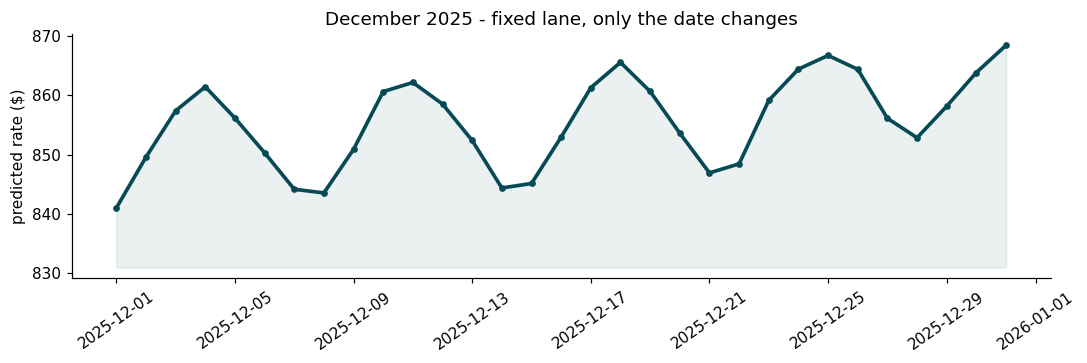


sanity: that lane appears 32 times in training, median rate $848.61 at ~362 miles
        December mean $855.53 - consistent with 9 months of drift


In [14]:
final = FreightRatePipeline(RunConfig()).fit(train, context_frames=(valid,))
dec = december.copy()
dec["predicted_rate"] = final.predict(dec)

print(f"range ${dec.predicted_rate.min():,.2f} .. ${dec.predicted_rate.max():,.2f}"
      f"  ({100*(dec.predicted_rate.max()/dec.predicted_rate.min()-1):.1f}% spread)")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(dec.date, dec.predicted_rate, color=TEAL, lw=2.4, marker="o", ms=3.4)
ax.fill_between(dec.date, dec.predicted_rate, dec.predicted_rate.min()-10, color=TEAL, alpha=.08)
ax.set(ylabel="predicted rate ($)", title="December 2025 - fixed lane, only the date changes")
ax.tick_params(axis="x", rotation=35); plt.tight_layout(); plt.show()

lane = train[(train.pickup=="Lexington") & (train.delivery=="Fort Wayne")]
print(f"\nsanity: that lane appears {len(lane)} times in training, median rate "
      f"${lane.posted_rate.median():,.2f} at ~{lane.distance.median():.0f} miles")
print(f"        December mean ${dec.predicted_rate.mean():,.2f} - consistent with 9 months of drift")

The weekly cycle is the dominant shape; the drift is the fitted market trend extrapolated
across December, adjusted by December's own daily `market_index`.

---

## Summary

Every decision is measured on the corrected temporal splits; the tables live in `reports/`.

| Decision | Evidence |
|---|---|
| Exclude corrupted labels | `model_selection.md` - about $10 of holdout MAE |
| Subtract `log(distance)` and the market level from the target | `model_selection.md` - about $9 each |
| Keep both level terms | `level_selection.md` - no variant wins on both geometries |
| City dropout for unseen cities | `cold_start.md` - about $10 on cold-start rows |
| Keep `quote_signal` out | `feature_selection.md` - helps the holdout, hurts the folds |
| Keep scikit-learn's estimator | `estimator_comparison.md` - alternatives inside the fold spread |

**Headline: see `reports/validation.md`** - the 61-day holdout, clean rows and all rows,
plus the rolling folds and the in-sample versus out-of-sample gap.

The reproducible path is the CLI, not this notebook:

```bash
python scripts/train.py --cv --random-kfold
python scripts/predict.py
python score.py --predictions validation_predictions.csv   --december-predictions data/december_chart_inputs.csv
FREIGHT_REQUIRE_SUBMISSION=1 python -m pytest
python scripts/verify_guards.py
```
